In [2]:
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.manifold import TSNE
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
dtm = pd.read_csv("tfidf_scores.csv", index_col = 0)

In [4]:
ra_names = set(dtm.index.tolist())
len(ra_names)

995

In [5]:
print("Number of dimensions per text:", len(dtm.columns))

Number of dimensions per text: 16026


In [6]:
sims = cosine_similarity(dtm)
sims = pd.DataFrame(sims, columns = dtm.index, index = dtm.index)
sims.iloc[:5, :5]

basename,ra_10924_2016,ra_10923_2016,ra_10925_2017,ra_10926_2017,ra_10927_2017
basename,,,,,
ra_10924_2016,1.000000,0.123936,0.130228,0.159211,0.130562
ra_10923_2016,0.123936,1.000000,0.058489,0.112565,0.078620
ra_10925_2017,0.130228,0.058489,1.000000,0.541950,0.063779
ra_10926_2017,0.159211,0.112565,0.541950,1.000000,0.112313
ra_10927_2017,0.130562,0.078620,0.063779,0.112313,1.000000


In [7]:
reducer = TSNE(
    n_components = 2,
    learning_rate = 'auto',
    init = 'random',
    angle = 0.35,
    random_state = 357,
    n_jobs = -1
)
reduced = reducer.fit_transform(sims)
vis = pd.DataFrame({'x': reduced[:,0], 'y': reduced[:,1], 'label': sims.index})

In [8]:
def sim_plot(data, hue = None, labels = None, n_colors = 3, palette = 'deep', figsize = (10, 10)):
    """Create a scatterplot and optionally color/label its points."""
    fig, ax = plt.subplots(figsize = figsize)
    pal = sns.color_palette(palette, n_colors = n_colors) if hue else None
    g = sns.scatterplot(
        x = 'x', y = 'y', hue = hue, palette = pal, alpha = 0.8,
        data = data, ax = ax
    )
    g.set(xticks = [], yticks = [], xlabel = 'Dim. 1', ylabel = 'Dim. 2')

    if labels:
        to_label = data[data['label'].isin(labels)]
        to_label[['x', 'y', 'label']].apply(lambda x: g.text(*x), axis = 1)

    plt.show()

# sim_plot(vis)

In [9]:
k = 10
agg = AgglomerativeClustering(n_clusters = k)
agg.fit(sims)

AgglomerativeClustering(n_clusters=10)

In [10]:
# including all labels
vis.loc[:, 'cluster'] = agg.labels_
sim_plot(vis, labels=ra_names, hue = 'cluster', n_colors=k, palette='bright', figsize=(100,100)) 

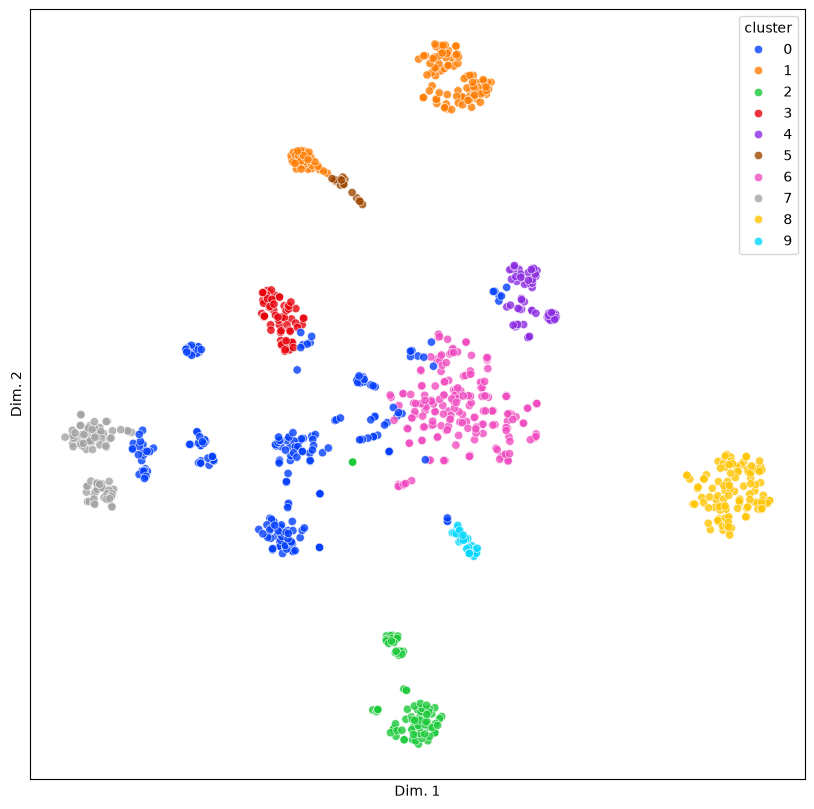

In [11]:
sim_plot(vis, hue = 'cluster', n_colors=k, palette='bright') 

In [12]:
n_sample = 5
for group in vis.groupby('cluster'):
    cluster, subset = group
    print(f"Cluster: {cluster}\n----------")
    samp = subset.sample(n_sample)
    for label in samp['label']:
        print(label)
    print("\n")

Cluster: 0
----------
ra_11019_2018
ra_10981_2018
ra_11651_2022
ra_11730_2022
ra_11471_2020


Cluster: 1
----------
ra_11513_2020
ra_11303_2019
ra_11492_2020
ra_11669_2022
ra_11507_2020


Cluster: 2
----------
ra_11436_2019
ra_11893_2022
ra_11063_2018
ra_11155_2018
ra_11611_2021


Cluster: 3
----------
ra_11113_2018
ra_11377_2019
ra_11143_2018
ra_11225_2019
ra_11100_2018


Cluster: 4
----------
ra_11008_2018
ra_11857_2022
ra_11088_2018
ra_11186_2019
ra_11752_2022


Cluster: 5
----------
ra_11918_2022
ra_11420_2019
ra_11842_2022
ra_11601_2021
ra_11357_2019


Cluster: 6
----------
ra_10927_2017
ra_11190_2019
ra_11131_2018
ra_11898_2022
ra_11711_2022


Cluster: 7
----------
ra_11021_2018
ra_11022_2018
ra_11615_2021
ra_11662_2022
ra_11074_2018


Cluster: 8
----------
ra_11289_2019
ra_11562_2021
ra_11723_2022
ra_11565_2021
ra_11085_2018


Cluster: 9
----------
ra_10949_2017
ra_10946_2017
ra_11810_2022
ra_11911_2022
ra_11777_2022




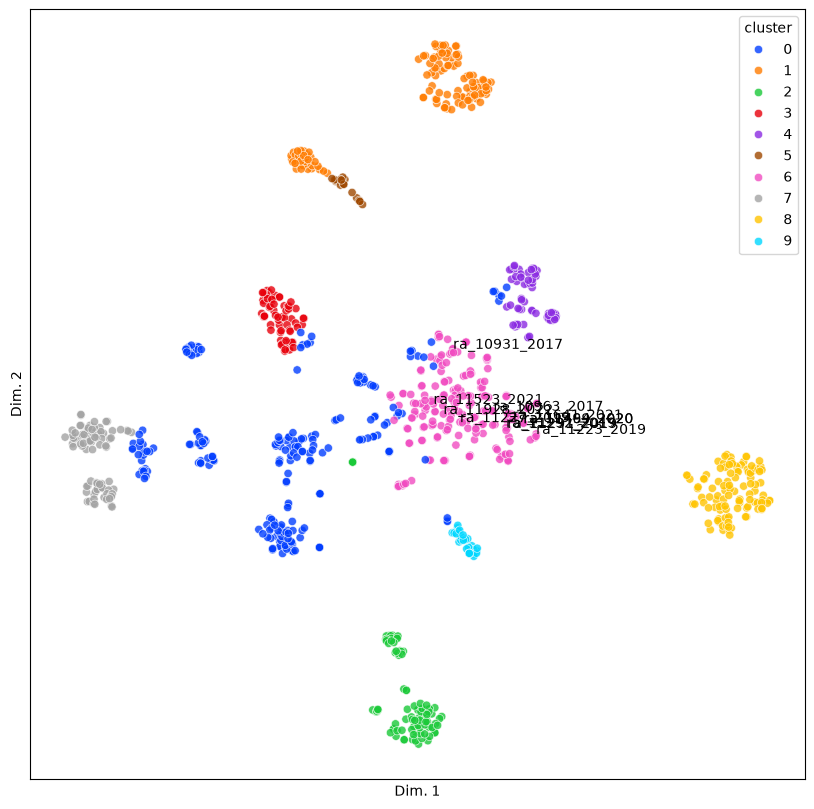

In [24]:
# RA's mentioned in the SONA (from Clustering Analysis file)
labels = [
    # 'illegal drug'
    "ra_11928_2022", # Separate Facility for Heinous Crimes Act
    "ra_11292_2019", # The Seal of Good Local Governance Act of 2019 - mentions "effective anti-illegal drugs campaign"
    # 'free tertiary'
    "ra_10931_2017", # Universal Access to Quality Tertiary Education Act
    # 'ofw'
    "ra_11227_2019", # Handbook for OFWs Act of 2018
    "ra_11641_2021", # Department of Migrant Workers Act
    # 'covid'
    "ra_11469_2020", # Bayanihan to Heal As One Act
    "ra_11494_2020", # Bayanihan to Recover As One Act
    "ra_11523_2021", # Financial Institutions Strategic Transfer (FIST) Act
    # 'tax reform'
    "ra_10963_2017", # Tax Reform for Acceleration and Inclusion (TRAIN)
    "ra_11223_2019", # Universal Health Care Act
    "ra_11291_2019", # Magna Carta of the Poor
]
sim_plot(vis, labels=labels, hue = 'cluster', palette='bright', n_colors=k) 